# 2. Daten verstehen

Ziel: Datentypen, fehlende Werte, Kündigungen und Umsatzmuster untersuchen. Die Diagramme werden in `docs/images/` gespeichert. Leerzeichen in `TotalCharges` sind zunächst Text und werden von `isna()` noch nicht als fehlend gezählt.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Notebook im Projektordner oder in notebooks/ starten.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.churn import load_churn

raw_telco = pd.read_csv(ROOT / "data/telco/WA_Fn-UseC_-Telco-Customer-Churn.csv")
telco = load_churn()
sales = pd.read_csv(ROOT / "data/rossmann/train_filtered.csv")
sales["Date"] = pd.to_datetime(sales["Date"])
images = ROOT / "docs/images"
images.mkdir(parents=True, exist_ok=True)
print("Rohe Datentypen:", raw_telco.dtypes, sep="\n")
print("Fehlende Werte nach Typkonvertierung:", telco.isna().sum(), sep="\n")

Rohe Datentypen:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
Fehlende Werte nach Typkonvertierung:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      

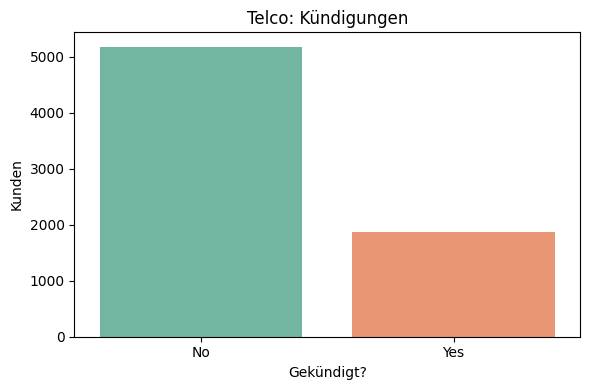

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=raw_telco, x="Churn", hue="Churn", palette="Set2", legend=False, ax=ax)
ax.set(title="Telco: Kündigungen", xlabel="Gekündigt?", ylabel="Kunden")
fig.tight_layout()
fig.savefig(images / "churn-distribution.png", dpi=150)
plt.show()

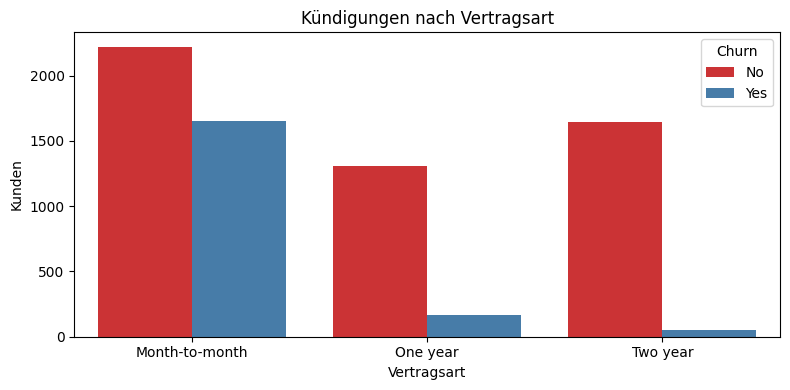

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=raw_telco, x="Contract", hue="Churn", palette="Set1", ax=ax)
ax.set(title="Kündigungen nach Vertragsart", xlabel="Vertragsart", ylabel="Kunden")
fig.tight_layout()
fig.savefig(images / "churn-by-contract.png", dpi=150)
plt.show()

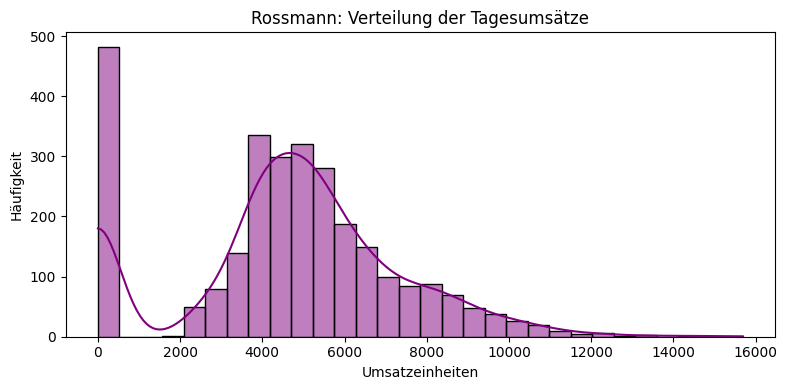

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=sales, x="Sales", bins=30, kde=True, color="purple", ax=ax)
ax.set(title="Rossmann: Verteilung der Tagesumsätze", xlabel="Umsatzeinheiten", ylabel="Häufigkeit")
fig.tight_layout()
fig.savefig(images / "sales-distribution.png", dpi=150)
plt.show()

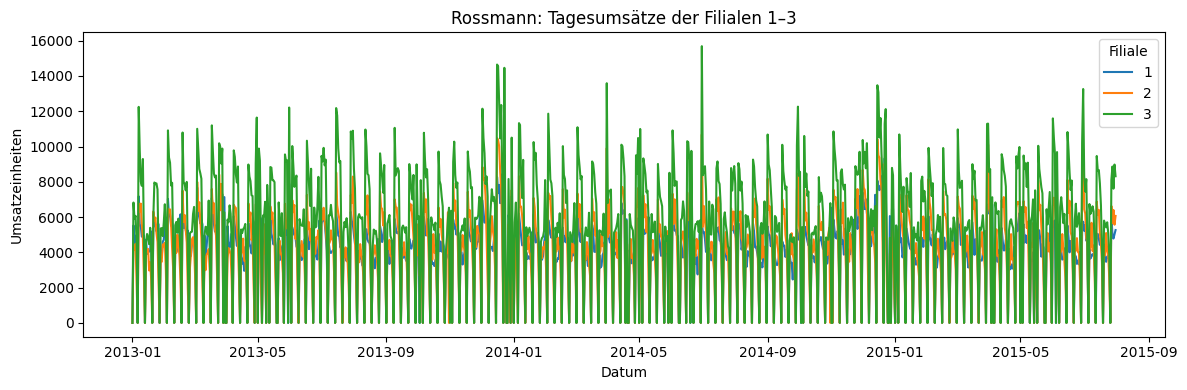

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(data=sales, x="Date", y="Sales", hue=sales["Store"].astype(str), ax=ax)
ax.set(title="Rossmann: Tagesumsätze der Filialen 1–3", xlabel="Datum", ylabel="Umsatzeinheiten")
ax.legend(title="Filiale")
fig.tight_layout()
fig.savefig(images / "sales-history.png", dpi=150)
plt.show()

Die Diagramme zeigen Zusammenhänge. Sie beweisen nicht, dass eine Vertragsart eine Kündigung verursacht. Rossmann enthält keine eigene Währungsspalte; die Achse zeigt daher Umsatzeinheiten.